# Lab 04 — CSP: tô màu đồ thị

Bài làm cho **4 bài thực hành** và toàn bộ mục **Assignment của notebook tô màu**:
biểu diễn CSP; kiểm tra phép gán; Backtracking, MRV, LCV; Forward Checking;
Min-Conflicts và thực nghiệm theo kích thước đồ thị.

**Cách đọc:** mỗi bài gồm mô hình/ý tưởng → mã thực hiện → kiểm chứng → nhận xét từ kết quả.
Chạy **Restart Kernel → Run All** để tái tạo bảng, hình và kết luận. Seed được cố định;
thời gian và các lần dừng theo thời gian có thể thay đổi giữa các máy.
Các thuật toán được tự cài đặt; NumPy/SciPy chỉ sinh dữ liệu, pandas/Matplotlib trình bày kết quả.

**Công cụ hỗ trợ:** OpenAI Codex được dùng để hỗ trợ xây dựng mã, kiểm thử và diễn giải.
**Team: Quý - Phúc - Tri - Khoa**

In [1]:
%matplotlib inline
from collections import Counter
from itertools import combinations, product
from time import perf_counter
import platform
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay
from IPython.display import display, Markdown

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
COLORS = ('red', 'blue', 'green', 'orange')
import scipy
import matplotlib
print('Môi trường:', platform.system(), platform.machine(), '| Python', platform.python_version())
display(pd.DataFrame({'thư viện': ['NumPy', 'SciPy', 'pandas', 'Matplotlib'],
                      'phiên bản': [np.__version__, scipy.__version__, pd.__version__, matplotlib.__version__]}))
print('Seed đồ thị minh họa: 1111; n = 10')

Môi trường: Windows AMD64 | Python 3.10.11


,thư viện,phiên bản
0,NumPy,2.2.6
1,SciPy,1.15.3
2,pandas,2.3.3
3,Matplotlib,3.10.7


Seed đồ thị minh họa: 1111; n = 10


## Bài 1. Biểu diễn CSP và sinh đồ thị

Với đồ thị vô hướng $G=(V,E)$, bài toán gồm:

- **Biến:** $X=\{X_0,\ldots,X_{n-1}\}$, mỗi biến là màu của một đỉnh. Trong mã dùng khóa chuỗi `'0'`, `'1'`, … để giữ cấu trúc của notebook gốc.
- **Miền:** $D_i=\{\mathrm{red,blue,green,orange}\}$ hoặc chỉ ba màu đầu.
- **Ràng buộc:** $X_i\ne X_j$ với mọi cạnh $\{i,j\}\in E$.

Danh sách `neighbors[i]` chứa mọi đỉnh nối với `i`. Mỗi cạnh xuất hiện trong hai danh sách
láng giềng; chỉ lưu cặp có **i < j** để mỗi ràng buộc vô hướng xuất hiện đúng một lần.
Điều này không làm mất chiều kiểm tra: điều kiện khác màu là đối xứng, và bảng `adjacency`
vẫn lưu cả hai chiều để thuật toán tra cứu nhanh.

,đỉnh,láng giềng
0,0,"[1, 2, 4, 5]"
1,1,"[0, 5, 7]"
2,2,"[0, 3, 4, 9]"
3,3,"[2, 4, 9]"
4,4,"[0, 2, 3, 5, 6, 8, 9]"
5,5,"[0, 1, 4, 6, 7]"
6,6,"[4, 5, 7, 8]"
7,7,"[1, 5, 6, 8]"
8,8,"[4, 6, 7, 9]"
9,9,"[2, 3, 4, 8]"


variables = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
domains = {'0': ['red', 'blue', 'green', 'orange'], '1': ['red', 'blue', 'green', 'orange'], '2': ['red', 'blue', 'green', 'orange'], '3': ['red', 'blue', 'green', 'orange'], '4': ['red', 'blue', 'green', 'orange'], '5': ['red', 'blue', 'green', 'orange'], '6': ['red', 'blue', 'green', 'orange'], '7': ['red', 'blue', 'green', 'orange'], '8': ['red', 'blue', 'green', 'orange'], '9': ['red', 'blue', 'green', 'orange']}
constraints = [('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')]
Số cạnh: 21


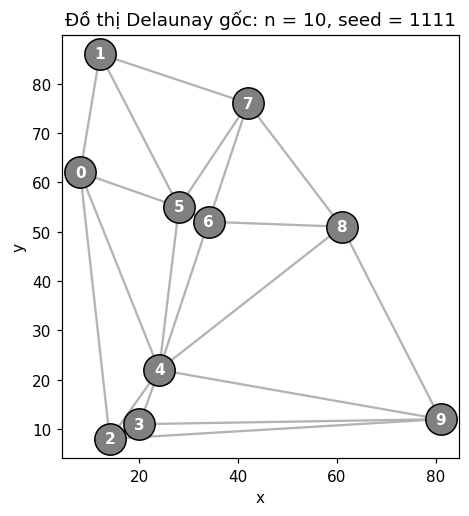

In [2]:
def make_csp(neighbors, colors=COLORS):
    """CSP tô màu: miền độc lập, cạnh một bản, adjacency hai chiều."""
    variables = [str(i) for i in range(len(neighbors))]
    edges = sorted({tuple(sorted((i, int(j))))
                    for i, row in enumerate(neighbors) for j in row if i != j})
    adjacency = {v: [] for v in variables}
    for i, j in edges:
        adjacency[str(i)].append(str(j))
        adjacency[str(j)].append(str(i))
    return {
        'variables': variables,
        'domains': {v: list(colors) for v in variables},
        'constraints': [(str(i), str(j)) for i, j in edges],
        'adjacency': adjacency,
    }


def generate_graph(n, seed, original=False):
    """Mẫu gốc dùng RandomState; các mẫu lớn dùng điểm liên tục tránh trùng tọa độ."""
    if original:
        points = np.random.RandomState(seed).randint(100, size=(n, 2))
    else:
        points = np.random.default_rng(seed).uniform(0, 100, size=(n, 2))
    points = points[np.argsort(points[:, 0])]
    tri = Delaunay(points)
    indptr, indices = tri.vertex_neighbor_vertices
    neighbors = [np.sort(indices[indptr[i]:indptr[i + 1]]).tolist()
                 for i in range(n)]
    return points, tri, neighbors


def draw_graph(points, csp, assignment=None, ax=None, title=''):
    """Đặt màu theo tên đỉnh; không phụ thuộc thứ tự chèn vào dictionary."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    for u, v in csp['constraints']:
        xy = points[[int(u), int(v)]]
        ax.plot(xy[:, 0], xy[:, 1], color='0.7', zorder=1)
    for v in csp['variables']:
        x, y = points[int(v)]
        color = assignment.get(v, 'lightgray') if assignment is not None else 'gray'
        ax.scatter(x, y, s=420, c=color, edgecolors='black', zorder=2)
        ax.text(x, y, v, color='white' if color != 'orange' else 'black',
                ha='center', va='center', weight='bold', zorder=3)
    ax.set(title=title, xlabel='x', ylabel='y', aspect='equal')
    return ax


n = 10
points, tri, neighbors = generate_graph(n, 1111, original=True)
csp4 = make_csp(neighbors, COLORS)
csp3 = make_csp(neighbors, COLORS[:3])
csp = csp4
display(pd.DataFrame({'đỉnh': range(n), 'láng giềng': neighbors}))
print('variables =', csp['variables'])
print('domains =', csp['domains'])
print('constraints =', csp['constraints'])
print('Số cạnh:', len(csp['constraints']))
assert sum(map(len, neighbors)) == 2 * len(csp['constraints'])
assert all(int(u) < int(v) for u, v in csp['constraints'])
assert csp['domains']['0'] is not csp['domains']['1']
draw_graph(points, csp, title='Đồ thị Delaunay gốc: n = 10, seed = 1111')
plt.show()

**Đầy đủ và hợp lệ là hai thuộc tính khác nhau.** Phép gán đầy đủ có giá trị cho mọi biến;
phép gán nhất quán có màu thuộc đúng miền và không vi phạm cạnh nào giữa các đỉnh đã gán.
Một phép gán từng phần có thể nhất quán nhưng chưa là nghiệm. **Nghiệm CSP** phải vừa đầy đủ,
vừa nhất quán. Đổi từ 4 xuống 3 màu chỉ thay miền, giữ nguyên biến và cạnh; có ít lựa chọn hơn,
thậm chí mất mọi nghiệm. Đồ thị phẳng có thể cần 4 màu, nên không được mặc định 3 màu luôn đủ.

## Bài 2. Kiểm tra tính đầy đủ và nhất quán

`complete()` chỉ trả lời đã gán đủ mọi biến hay chưa. `consistent()` kiểm tra biến/màu hợp lệ
và các ràng buộc có đủ hai đầu đã gán. Bổ sung kiểm tra miền giúp loại các phép gán màu không
thuộc CSP; hàm gốc chỉ kiểm tra cạnh nên bỏ sót trường hợp này.
Phép gán rỗng nhất quán vì chưa có ràng buộc nào bị vi phạm.

In [3]:
def complete(assignment, csp):
    return all(v in assignment for v in csp['variables'])


def consistent(assignment, csp):
    if any(v not in csp['domains'] or color not in csp['domains'][v]
           for v, color in assignment.items()):
        return False
    return all(u not in assignment or v not in assignment
               or assignment[u] != assignment[v]
               for u, v in csp['constraints'])


def is_solution(assignment, csp):
    return assignment is not None and complete(assignment, csp) and consistent(assignment, csp)


# K3 có nghiệm 3 màu biết trước; không dùng kết quả solver làm đáp án mong đợi.
triangle = make_csp([[1, 2], [0, 2], [0, 1]], COLORS[:3])
u, v = csp['constraints'][0]
cases = [
    ('Rỗng', csp, {}, False, True),
    ('Một phần hợp lệ', csp, {u: 'red', v: 'blue'}, False, True),
    ('Một phần xung đột trên cạnh', csp, {u: 'red', v: 'red'}, False, False),
    ('Đầy đủ nhưng mọi đỉnh đỏ', csp, dict.fromkeys(csp['variables'], 'red'), True, False),
    ('Đầy đủ, hợp lệ trên K3', triangle, {'0': 'red', '1': 'blue', '2': 'green'}, True, True),
    ('Màu ngoài miền', csp, {u: 'purple'}, False, False),
    ('Biến ngoài CSP', csp, {'unknown': 'red'}, False, False),
]
rows = []
for name, problem, assignment, want_complete, want_consistent in cases:
    got = complete(assignment, problem), consistent(assignment, problem)
    assert got == (want_complete, want_consistent), name
    rows.append({'ca kiểm thử': name, 'mong đợi complete': want_complete,
                 'thực tế complete': got[0], 'mong đợi consistent': want_consistent,
                 'thực tế consistent': got[1], 'đạt': True})
display(pd.DataFrame(rows))

,ca kiểm thử,mong đợi complete,thực tế complete,mong đợi consistent,thực tế consistent,đạt
0,Rỗng,False,False,True,True,True
1,Một phần hợp lệ,False,False,True,True,True
2,Một phần xung đột trên cạnh,False,False,False,False,True
3,Đầy đủ nhưng mọi đỉnh đỏ,True,True,False,False,True
4,"Đầy đủ, hợp lệ trên K3",True,True,True,True,True
5,Màu ngoài miền,False,False,False,False,True
6,Biến ngoài CSP,False,False,False,False,True


**Đọc bảng:** dòng “đầy đủ nhưng mọi đỉnh đỏ” có `complete=True`, `consistent=False`:
đã gán đủ nhưng có cạnh cùng màu. Dòng “một phần hợp lệ” có kết quả ngược lại:
chưa gán đủ nhưng không có xung đột hiện tại. Vì vậy `complete()` không thay thế được
`consistent()`. Cấu trúc lưu trữ gồm `variables` (danh sách biến), `domains` (dict biến →
danh sách màu), `constraints` (danh sách cặp phải khác màu), thêm `adjacency` để tăng tốc tra cứu.

## Bài 3. Backtracking và thứ tự chọn biến/giá trị

**Phiên bản gốc:** chọn biến chưa gán đầu tiên và thử màu theo thứ tự miền.
Nếu nhất quán thì đi sâu; nếu mọi màu đều thất bại thì xóa phép gán và quay lui.

**MRV:** chọn biến chưa gán có ít **màu còn hợp lệ** nhất. Không dùng độ dài miền gốc,
vì các miền ban đầu đều bằng nhau. Khi hòa, giữ thứ tự biến ban đầu để so sánh dễ kiểm chứng.

**LCV:** với từng màu ứng viên, đếm số giá trị sẽ bị cấm ở các láng giềng chưa gán;
thử màu làm mất ít lựa chọn nhất trước. LCV giữ cơ hội cho các biến kế tiếp nhưng tốn chi phí
tính điểm. MRV/LCV chỉ đổi thứ tự tìm kiếm, không bỏ nghiệm.

Quy ước thống kê:

- `COUNT`: số lần vào hàm đệ quy, tính cả nút gốc và nút nghiệm, giống notebook ban đầu.
- `attempts`: số lần thử gán một màu, kể cả gán bị loại do xung đột; đây là chỉ số bổ sung mà Assignment yêu cầu.
- `backtracks`: số nút đã thử hết lựa chọn và trả về thất bại.
- `status=solved`: tìm được nghiệm; `unsat`: duyệt hết cây nên chứng minh vô nghiệm;
  `limit`: hết ngân sách, chưa kết luận có nghiệm hay không.

In [4]:
def legal_values(var, assignment, csp, domains=None):
    current = csp['domains'] if domains is None else domains
    forbidden = {assignment[u] for u in csp['adjacency'][var] if u in assignment}
    return [value for value in current[var] if value not in forbidden]


def select_unassigned_var(assignment, csp, strategy='first', domains=None):
    unassigned = [v for v in csp['variables'] if v not in assignment]
    if not unassigned:
        return None
    if strategy == 'first':
        return unassigned[0]
    if strategy == 'mrv':
        return min(unassigned, key=lambda v: len(legal_values(v, assignment, csp, domains)))
    raise ValueError('Unknown variable strategy')


def order_domain(assignment, var, csp, strategy='natural', domains=None):
    current = csp['domains'] if domains is None else domains
    if strategy == 'natural':
        return list(current[var])
    if strategy != 'lcv':
        raise ValueError('Unknown value strategy')
    values = legal_values(var, assignment, csp, current)
    neighbor_domains = [legal_values(u, assignment, csp, current)
                        for u in csp['adjacency'][var] if u not in assignment]
    return sorted(values, key=lambda color: sum(color in d for d in neighbor_domains))


# Kiểm thử cho thấy MRV nhìn miền hợp lệ, LCV nhìn tác động tương lai.
path = make_csp([[1], [0, 2], [1]], COLORS[:3])
assert select_unassigned_var({'2': 'red'}, path, 'first') == '0'
assert select_unassigned_var({'2': 'red'}, path, 'mrv') == '1'
assert order_domain({'2': 'red'}, '0', path, 'lcv') == ['red', 'blue', 'green']
print('Chọn biến khi đã gán đỉnh 2 = red trên đường 0—1—2:')
print('Gốc:', select_unassigned_var({'2': 'red'}, path))
print('MRV:', select_unassigned_var({'2': 'red'}, path, 'mrv'))
print('MRV và LCV: kiểm thử đạt.')

Chọn biến khi đã gán đỉnh 2 = red trên đường 0—1—2:
Gốc: 0
MRV: 1
MRV và LCV: kiểm thử đạt.


## Bài 4a. Forward Checking và hoàn tác miền

Sau khi gán $X_v=c$, Forward Checking xóa $c$ khỏi miền mọi láng giềng chưa gán.
Nếu một miền rỗng, nhánh hiện tại thất bại ngay. Mỗi lần xóa lưu `(biến, vị trí, màu)`
vào **trail**; quay lui phục hồi theo thứ tự đảo để khôi phục cả nội dung và thứ tự miền.
Mỗi lần giải sao chép miền của CSP, nên không làm thay đổi dữ liệu đầu vào.

Forward Checking chỉ truyền tác động của phép gán mới sang láng giềng trực tiếp;
không thực hiện lan truyền đầy đủ như AC-3. Đoạn solver sau dùng cùng một lõi cho các cấu hình,
giúp so sánh tác động của MRV, LCV và Forward Checking.

,màu,thuật toán,status,COUNT,attempts,backtracks,pruned,wipeouts,ms
0,4,BT gốc,solved,11,23,0,0,0,0.203
1,4,BT + MRV,solved,11,24,0,0,0,0.390
2,4,BT + MRV + LCV,solved,11,10,0,0,0,0.372
3,4,BT + FC,solved,11,10,0,18,0,1.852
4,4,BT + MRV + LCV + FC,solved,11,10,0,20,0,0.367
5,3,BT gốc,unsat,70,210,70,0,0,0.629
6,3,BT + MRV,unsat,34,102,34,0,0,0.831
7,3,BT + MRV + LCV,unsat,34,33,34,0,0,1.748
8,3,BT + FC,unsat,34,57,34,108,24,0.782
9,3,BT + MRV + LCV + FC,unsat,28,33,28,90,6,3.602


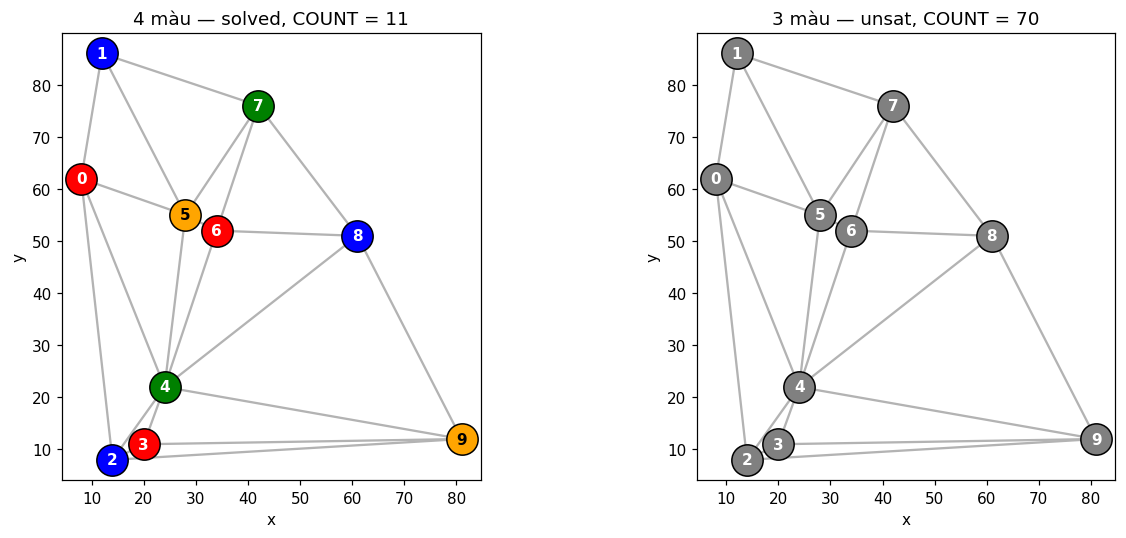

Nghiệm 4 màu: {'0': 'red', '1': 'blue', '2': 'blue', '3': 'red', '4': 'green', '5': 'orange', '6': 'red', '7': 'green', '8': 'blue', '9': 'orange'}
Nghiệm 3 màu: None


In [5]:
def forward_check(var, value, assignment, csp, domains):
    trail = []
    for u in csp['adjacency'][var]:
        if u in assignment or value not in domains[u]:
            continue
        index = domains[u].index(value)
        domains[u].pop(index)
        trail.append((u, index, value))
        if not domains[u]:
            return False, trail
    return True, trail


def restore_domains(domains, trail):
    for var, index, value in reversed(trail):
        domains[var].insert(index, value)


COUNT = 0


def backtrack_search(csp, variable_order='first', value_order='natural',
                     use_fc=False, max_attempts=None, time_limit=None):
    """Tìm kiếm đầy đủ nếu không đặt giới hạn. Các miền FC luôn được phục hồi."""
    global COUNT
    COUNT = 0
    started = perf_counter()
    stats = {'COUNT': 0, 'attempts': 0, 'backtracks': 0,
             'pruned': 0, 'wipeouts': 0}
    domains = {v: list(d) for v, d in csp['domains'].items()}
    assignment = {}

    class BudgetExceeded(Exception):
        pass

    def check_budget():
        if time_limit is not None and perf_counter() - started >= time_limit:
            raise BudgetExceeded
        if max_attempts is not None and stats['attempts'] >= max_attempts:
            raise BudgetExceeded

    def backtrack():
        stats['COUNT'] += 1
        if complete(assignment, csp):
            return dict(assignment)
        check_budget()
        var = select_unassigned_var(assignment, csp, variable_order, domains)
        for value in order_domain(assignment, var, csp, value_order, domains):
            check_budget()
            stats['attempts'] += 1
            assignment[var] = value
            trail = []
            try:
                # Tương đương consistent trên nhánh đang nhất quán:
                # chỉ các cạnh chạm biến mới có thể vừa phát sinh xung đột.
                if any(assignment.get(u) == value for u in csp['adjacency'][var]):
                    continue
                feasible = True
                if use_fc:
                    feasible, trail = forward_check(var, value, assignment, csp, domains)
                    stats['pruned'] += len(trail)
                    stats['wipeouts'] += int(not feasible)
                if feasible:
                    result = backtrack()
                    if result is not None:
                        return result
            finally:
                restore_domains(domains, trail)
                del assignment[var]
        stats['backtracks'] += 1
        return None

    try:
        solution = backtrack()
        status = 'solved' if solution is not None else 'unsat'
    except BudgetExceeded:
        solution, status = None, 'limit'
    COUNT = stats['COUNT']
    assert domains == csp['domains'], 'Miền không được hoàn tác chính xác'
    assert not assignment, 'Phép gán tạm phải được dọn sau khi kết thúc'
    assert solution is None or is_solution(solution, csp)
    return {'solution': solution, 'status': status,
            'seconds': perf_counter() - started, **stats}


BT_VARIANTS = {
    'BT gốc': dict(),
    'BT + MRV': dict(variable_order='mrv'),
    'BT + MRV + LCV': dict(variable_order='mrv', value_order='lcv'),
    'BT + FC': dict(use_fc=True),
    'BT + MRV + LCV + FC': dict(variable_order='mrv', value_order='lcv', use_fc=True),
}

demo_results = {}
for k, problem in [(4, csp4), (3, csp3)]:
    for name, options in BT_VARIANTS.items():
        demo_results[k, name] = backtrack_search(problem, **options)
display(pd.DataFrame([
    {'màu': k, 'thuật toán': name,
     **{key: result[key] for key in ['status', 'COUNT', 'attempts', 'backtracks', 'pruned', 'wipeouts']},
     'ms': 1000 * result['seconds']}
    for (k, name), result in demo_results.items()
]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, k in zip(axes, [4, 3]):
    result = demo_results[k, 'BT gốc']
    draw_graph(points, csp4 if k == 4 else csp3, result['solution'], ax,
               f'{k} màu — {result["status"]}, COUNT = {result["COUNT"]}')
plt.tight_layout()
plt.show()
for k in [4, 3]:
    print(f'Nghiệm {k} màu:', demo_results[k, 'BT gốc']['solution'])

In [6]:
# Nhận xét sinh từ đúng kết quả đã chạy, không giả định trước đồ thị 3 màu có nghiệm.
base = demo_results[4, 'BT gốc']
mrv = demo_results[4, 'BT + MRV']
lcv = demo_results[4, 'BT + MRV + LCV']
fc = demo_results[4, 'BT + MRV + LCV + FC']
r3 = demo_results[3, 'BT gốc']
display(Markdown(
    f'**Kết quả cùng đồ thị:** với 4 màu, BT gốc thăm **{base["COUNT"]} nút**, '
    f'thử **{base["attempts"]} phép gán**; MRV lần lượt là '
    f'**{mrv["COUNT"]} / {mrv["attempts"]}**, MRV+LCV là '
    f'**{lcv["COUNT"]} / {lcv["attempts"]}**, thêm FC là '
    f'**{fc["COUNT"]} / {fc["attempts"]}**. '
    f'Với 3 màu, duyệt đầy đủ cho trạng thái **{r3["status"]}** '
    f'sau **{r3["COUNT"]} nút**. '
    'Ít nút hơn chưa bảo đảm nhanh hơn: tính miền MRV và điểm LCV cũng tốn thời gian.'
))

**Kết quả cùng đồ thị:** với 4 màu, BT gốc thăm **11 nút**, thử **23 phép gán**; MRV lần lượt là **11 / 24**, MRV+LCV là **11 / 10**, thêm FC là **11 / 10**. Với 3 màu, duyệt đầy đủ cho trạng thái **unsat** sau **70 nút**. Ít nút hơn chưa bảo đảm nhanh hơn: tính miền MRV và điểm LCV cũng tốn thời gian.

### Kiểm chứng Backtracking và Forward Checking

Kiểm tra một nhánh rỗng miền rồi khôi phục; kiểm tra cả chứng minh vô nghiệm và dừng ngân sách.
Tiếp theo đối chiếu **cả 5 biến thể** với vét cạn độc lập trên mọi đồ thị đơn 4 đỉnh
($2^6=64$ đồ thị), với cả 2 và 3 màu. Vét cạn chỉ dùng để kiểm chứng trên dữ liệu nhỏ,
không dùng trong thực nghiệm hiệu năng.

In [7]:
# Miền rỗng phải được khôi phục cả khi forward_check trả False giữa chừng.
edge = make_csp([[1], [0]], ['red'])
local_domains = {v: list(d) for v, d in edge['domains'].items()}
ok, trail = forward_check('0', 'red', {'0': 'red'}, edge, local_domains)
assert not ok and local_domains['1'] == []
restore_domains(local_domains, trail)
assert local_domains == edge['domains']

k4 = make_csp([[j for j in range(4) if j != i] for i in range(4)], COLORS[:3])
for options in BT_VARIANTS.values():
    assert backtrack_search(k4, **options)['status'] == 'unsat'
assert backtrack_search(csp4, max_attempts=0)['status'] == 'limit'
assert backtrack_search(csp4, time_limit=0)['status'] == 'limit'


def brute_force_exists(problem):
    variables = problem['variables']
    return any(consistent(dict(zip(variables, values)), problem)
               for values in product(*(problem['domains'][v] for v in variables)))


checked = 0
possible_edges = list(combinations(range(4), 2))
for mask in range(1 << len(possible_edges)):
    adjacency = [[] for _ in range(4)]
    for bit, (i, j) in enumerate(possible_edges):
        if mask & (1 << bit):
            adjacency[i].append(j)
            adjacency[j].append(i)
    for k in [2, 3]:
        problem = make_csp(adjacency, COLORS[:k])
        expected = brute_force_exists(problem)
        before = {v: list(d) for v, d in problem['domains'].items()}
        for name, options in BT_VARIANTS.items():
            result = backtrack_search(problem, **options)
            assert (result['status'] == 'solved') == expected, (mask, k, name)
            assert result['solution'] is None or is_solution(result['solution'], problem)
            assert problem['domains'] == before
            checked += 1
print(f'Đạt {checked} đối chiếu thuật toán với vét cạn; FC hoàn tác đúng; K4/3 màu vô nghiệm.')

Đạt 640 đối chiếu thuật toán với vét cạn; FC hoàn tác đúng; K4/3 màu vô nghiệm.


## Bài 4b. Min-Conflicts có khởi động lại

1. Khởi tạo **phép gán đầy đủ ngẫu nhiên**; phép gán này được phép có xung đột.
2. Chọn ngẫu nhiên một đỉnh đang vi phạm ít nhất một cạnh.
3. Với đỉnh đó, tính số láng giềng cùng màu cho từng màu trong miền, rồi chọn ngẫu nhiên
   trong các màu có số vi phạm nhỏ nhất. Khi màu hiện tại cũng tốt nhất, ưu tiên đổi sang màu
   tốt nhất khác nếu có, để di chuyển trên vùng bằng phẳng.
4. Dừng khi không còn cạnh vi phạm; nếu hết số bước thì tạo phép gán mới, tối đa số restart quy định.

Vì thuật toán có thể giảm hoặc giữ nguyên số xung đột, mã đếm riêng:
`improving_moves` (giảm số cạnh vi phạm, tương ứng **uphill** nếu tối đa hóa $-h$),
`sideways_moves` (không đổi), `worsening_moves` (tăng), và `restarts` (không tính khởi tạo đầu).
`steps` tính mọi lần thử sửa một biến, kể cả khi giữ nguyên màu.
Miền ứng viên có cả màu hiện tại nên trong mỗi lần khởi tạo, số xung đột không tăng;
`worsening_moves` bằng 0 ở cài đặt này. `sideways_moves` gồm cả bước đổi màu giữ h và lần giữ màu;
`changed_moves` chỉ đếm lần thực sự đổi màu. Restart có thể làm h tăng nhưng được đếm riêng.

Để cập nhật nhanh, với mỗi đỉnh giữ bộ đếm số láng giềng theo màu; sau mỗi lần đổi màu chỉ
cập nhật láng giềng của đỉnh đó. Tập đỉnh đang xung đột được quản lý bằng danh sách và chỉ mục
để thêm/xóa/chọn ngẫu nhiên nhanh. Lưu trạng thái tốt nhất để báo số xung đột còn lại khi hết hạn.
Min-Conflicts không có tính đầy đủ: thất bại trong ngân sách **không chứng minh vô nghiệm**.

,màu,status,best_conflicts,steps,improving_moves,sideways_moves,worsening_moves,restarts
0,4,solved,0,4,4,0,0,0
1,3,limit,2,4000,14,3986,0,3


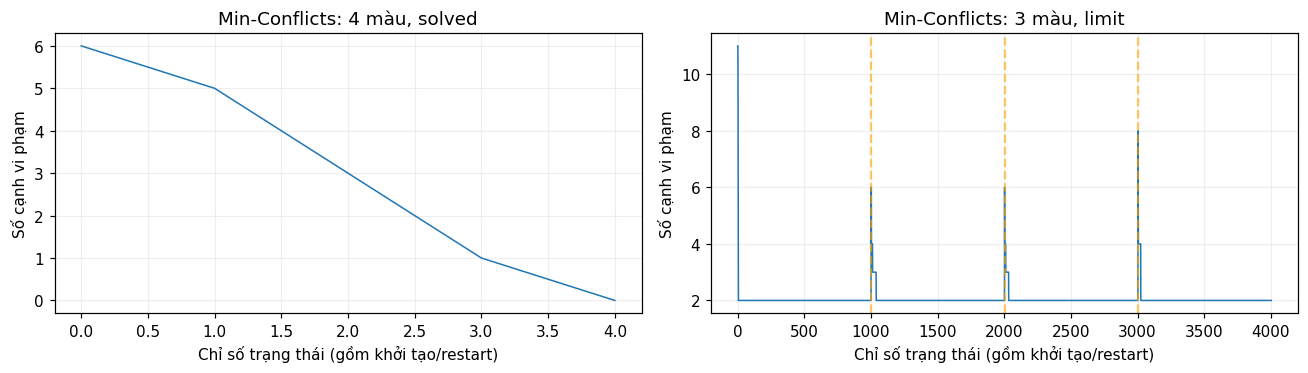

In [8]:
def conflict_count(assignment, csp):
    return sum(assignment[u] == assignment[v] for u, v in csp['constraints'])


def min_conflicts(csp, seed=0, max_steps=3000, max_restarts=4,
                  time_limit=None, record_history=False):
    rng = random.Random(seed)
    started = perf_counter()
    variables = csp['variables']
    stats = dict(steps=0, improving_moves=0, sideways_moves=0,
                 worsening_moves=0, changed_moves=0, restarts=0)
    best_assignment, best_conflicts = None, float('inf')
    history, restart_at = [], []

    def finish(solution, status):
        assert solution is None or is_solution(solution, csp)
        assert best_assignment is not None
        assert conflict_count(best_assignment, csp) == best_conflicts
        assert stats['steps'] == (stats['improving_moves'] + stats['sideways_moves']
                                  + stats['worsening_moves'])
        return {'solution': solution, 'status': status, 'best_assignment': best_assignment,
                'best_conflicts': best_conflicts, 'seconds': perf_counter() - started,
                'history': history, 'restart_at': restart_at, **stats}

    for restart in range(max_restarts + 1):
        stats['restarts'] = restart
        assignment = {v: rng.choice(csp['domains'][v]) for v in variables}
        counts = {v: Counter(assignment[u] for u in csp['adjacency'][v]) for v in variables}
        h = conflict_count(assignment, csp)
        active = [v for v in variables if counts[v][assignment[v]] > 0]
        positions = {v: i for i, v in enumerate(active)}

        def sync(v):
            conflicted = counts[v][assignment[v]] > 0
            if conflicted and v not in positions:
                positions[v] = len(active)
                active.append(v)
            elif not conflicted and v in positions:
                index = positions.pop(v)
                last = active.pop()
                if index < len(active):
                    active[index] = last
                    positions[last] = index

        if record_history:
            if restart:
                restart_at.append(len(history))
            history.append(h)
        if h < best_conflicts:
            best_assignment, best_conflicts = dict(assignment), h
        for _ in range(max_steps):
            if h == 0:
                return finish(dict(assignment), 'solved')
            if time_limit is not None and perf_counter() - started >= time_limit:
                return finish(None, 'limit')
            var = rng.choice(active)
            old = assignment[var]
            minimum = min(counts[var][color] for color in csp['domains'][var])
            candidates = [c for c in csp['domains'][var] if counts[var][c] == minimum]
            alternatives = [c for c in candidates if c != old]
            new = rng.choice(alternatives or candidates)
            delta = counts[var][new] - counts[var][old]
            stats['steps'] += 1
            stats['improving_moves' if delta < 0 else
                  'worsening_moves' if delta > 0 else 'sideways_moves'] += 1
            if new != old:
                stats['changed_moves'] += 1
                assignment[var] = new
                for u in csp['adjacency'][var]:
                    counts[u][old] -= 1
                    counts[u][new] += 1
                    sync(u)
                sync(var)
                h += delta
            if h < best_conflicts:
                best_assignment, best_conflicts = dict(assignment), h
            if record_history:
                # Kiểm tra phép cập nhật gia tăng trên các lần chạy minh họa.
                assert h == conflict_count(assignment, csp)
                history.append(h)
        # Lần đổi màu cuối cùng cũng có thể vừa đạt nghiệm.
        if h == 0:
            return finish(dict(assignment), 'solved')
        if time_limit is not None and perf_counter() - started >= time_limit:
            return finish(None, 'limit')
    return finish(None, 'limit')


mc_demo = {k: min_conflicts(problem, seed=2026, max_steps=1000,
                           max_restarts=3, record_history=True)
           for k, problem in [(4, csp4), (3, csp3)]}
display(pd.DataFrame([
    {'màu': k, **{field: r[field] for field in
                 ['status', 'best_conflicts', 'steps', 'improving_moves',
                  'sideways_moves', 'worsening_moves', 'restarts']}}
    for k, r in mc_demo.items()
]))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, (k, result) in zip(axes, mc_demo.items()):
    ax.plot(result['history'], linewidth=1)
    for location in result['restart_at']:
        ax.axvline(location, color='orange', linestyle='--', alpha=0.6)
    ax.set(title=f'Min-Conflicts: {k} màu, {result["status"]}',
           xlabel='Chỉ số trạng thái (gồm khởi tạo/restart)', ylabel='Số cạnh vi phạm')
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [9]:
# MC phải báo limit cho K4/3 màu, không được dùng unsat.
mc_unsat = min_conflicts(k4, seed=7, max_steps=20, max_restarts=2, record_history=True)
assert mc_unsat['status'] == 'limit' and mc_unsat['best_conflicts'] >= 1
assert mc_unsat['restarts'] == 2 and mc_unsat['steps'] == 60
isolated = make_csp([[], [], []], COLORS[:3])
assert min_conflicts(isolated)['status'] == 'solved'
zero_budget = min_conflicts(k4, max_steps=0, max_restarts=0)
assert zero_budget['status'] == 'limit' and zero_budget['steps'] == 0
# Nhiều seed kiểm chứng bộ đếm gia tăng và nghiệm trả về.
for seed in range(20):
    result = min_conflicts(triangle, seed=seed, max_steps=50,
                           max_restarts=2, record_history=True)
    assert result['status'] == 'solved' and is_solution(result['solution'], triangle)
print('Đạt kiểm thử Min-Conflicts: xung đột, restart, ngân sách, đỉnh cô lập, 20 seed K3.')

Đạt kiểm thử Min-Conflicts: xung đột, restart, ngân sách, đỉnh cô lập, 20 seed K3.


## Thực nghiệm tổng hợp theo yêu cầu Assignment

**Thiết kế:** $n\in\{10,20,40,80,160\}$; mỗi $n$ có **5 đồ thị độc lập**,
seed `1111..1115`. Mỗi đồ thị được dùng nguyên trạng cho 3/4 màu và tất cả thuật toán.
Riêng hình minh họa trước đó dùng đúng bộ sinh số nguyên của notebook gốc; ở thí nghiệm
này dùng tọa độ liên tục để tránh điểm trùng khi tăng $n$.

Mỗi lần chạy có giới hạn **0,4 giây**. Backtracking thêm giới hạn **30.000 lần thử gán**;
Min-Conflicts tối đa **3.000 bước/lần khởi tạo**, **4 restart** (5 lần khởi tạo).
Không tính thời gian sinh đồ thị, vẽ và xuất bảng vào thời gian giải.
Đây là so sánh theo ngân sách thực dụng; mức 0,4 giây có thể khiến số bước trước khi dừng
phụ thuộc tốc độ máy. Các lần chạy bị cắt được ghi rõ, không gọi là vô nghiệm.

Báo cáo cả tỷ lệ tìm nghiệm trên **tất cả** đồ thị và tỷ lệ trên những đồ thị đã được
kiểm chứng có nghiệm. Với nhóm chưa xác định tính thỏa được,
tỷ lệ thành công thấp có thể do vô nghiệm hoặc ngân sách, không chỉ do thuật toán yếu.

In [10]:
SIZES = [10, 20, 40, 80, 160]
GRAPH_SEEDS = list(range(1111, 1116))
TIME_LIMIT = 0.4
MAX_ATTEMPTS = 30_000
graph_bank = {}
edge_rows, raw_rows = [], []

for size in SIZES:
    for graph_seed in GRAPH_SEEDS:
        xy, triangulation, adjacency = generate_graph(size, graph_seed)
        graph_bank[size, graph_seed] = (xy, adjacency)
        graph4 = make_csp(adjacency, COLORS)
        m = len(graph4['constraints'])
        hull_size = len(np.unique(triangulation.convex_hull))
        # Công thức cạnh của phép tam giác hóa phẳng, ở vị trí tổng quát.
        assert m == 3 * size - 3 - hull_size
        edge_rows.append(dict(n=size, seed=graph_seed, edges=m, hull=hull_size,
                              mean_degree=2 * m / size, edge_ratio=m / size))
        for k in [3, 4]:
            problem = make_csp(adjacency, COLORS[:k])
            for name, options in BT_VARIANTS.items():
                result = backtrack_search(problem, **options, max_attempts=MAX_ATTEMPTS,
                                          time_limit=TIME_LIMIT)
                raw_rows.append(dict(n=size, seed=graph_seed, colors=k, algorithm=name,
                                     edges=m, **{key: value for key, value in result.items()
                                                if key != 'solution'}))
            result = min_conflicts(problem, seed=graph_seed + 100_000 * k,
                                   max_steps=3000, max_restarts=4, time_limit=TIME_LIMIT)
            raw_rows.append(dict(n=size, seed=graph_seed, colors=k,
                                 algorithm='Min-Conflicts', edges=m,
                                 **{key: value for key, value in result.items()
                                    if key not in ['solution', 'best_assignment', 'history', 'restart_at']}))

raw = pd.DataFrame(raw_rows)
edge_data = pd.DataFrame(edge_rows)
raw['solved'] = raw['status'].eq('solved')
raw['unsat'] = raw['status'].eq('unsat')
raw['limit'] = raw['status'].eq('limit')
print(f'Hoàn tất {len(edge_data)} đồ thị và {len(raw)} lần chạy.')

Hoàn tất 25 đồ thị và 300 lần chạy.


,n,instances,mean_edges,min_edges,max_edges,mean_degree,mean_edges_per_n
0,10,5,21.0,20,23,4.200,2.100
1,20,5,49.8,47,52,4.980,2.490
2,40,5,109.4,108,110,5.470,2.735
3,80,5,226.8,226,228,5.670,2.835
4,160,5,465.2,460,470,5.815,2.907


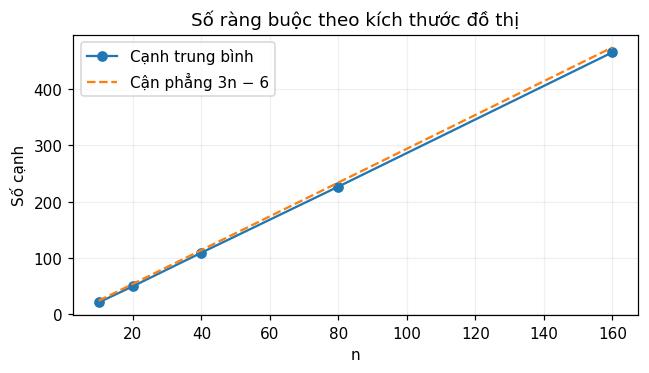

In [11]:
edge_summary = edge_data.groupby('n', as_index=False).agg(
    instances=('seed', 'count'), mean_edges=('edges', 'mean'),
    min_edges=('edges', 'min'), max_edges=('edges', 'max'),
    mean_degree=('mean_degree', 'mean'), mean_edges_per_n=('edge_ratio', 'mean'))
display(edge_summary.round(3))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(edge_summary['n'], edge_summary['mean_edges'], 'o-', label='Cạnh trung bình')
ax.plot(SIZES, [3 * size - 6 for size in SIZES], '--', label='Cận phẳng 3n − 6')
ax.set(xlabel='n', ylabel='Số cạnh', title='Số ràng buộc theo kích thước đồ thị')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Giải thích số cạnh:** đồ thị tam giác hóa có $m=3n-3-h$, với $h$ là số đỉnh trên bao lồi.
Từ Euler $n-m+f=2$ và đếm các cạnh theo mặt $3(f-1)+h=2m$, suy ra công thức trên.
Vì vậy số ràng buộc tăng tuyến tính theo $n$, nằm dưới $3n-6$ khi $n\ge3$;
bậc trung bình $2m/n$ tiến gần 6 khi phần bao lồi nhỏ so với $n$.
Số cạnh tuyến tính không có nghĩa Backtracking tuyến tính: số phép gán có thể tăng theo $k^n$.

In [12]:
# Tính trạng thái của từng đồ thị từ kết quả có chứng cứ, không suy từ thất bại MC.
keys = ['n', 'seed', 'colors']
proof_rows = []
for key, group in raw.groupby(keys):
    any_sat = group['status'].eq('solved').any()
    any_unsat = group['status'].eq('unsat').any()
    assert not (any_sat and any_unsat), 'Thuật toán mâu thuẫn về tính thỏa được'
    proof_rows.append(dict(zip(keys, key), proof='sat' if any_sat else 'unsat' if any_unsat else 'unknown'))
proofs = pd.DataFrame(proof_rows)
raw = raw.merge(proofs, on=keys, validate='many_to_one')
summary = raw.groupby(['n', 'colors', 'algorithm'], as_index=False).agg(
    runs=('status', 'size'), solved=('solved', 'sum'), unsat=('unsat', 'sum'),
    limited=('limit', 'sum'), success_pct=('solved', lambda s: 100 * s.mean()),
    mean_ms=('seconds', lambda s: 1000 * s.mean()),
    mean_COUNT=('COUNT', 'mean'), mean_attempts=('attempts', 'mean'),
    mean_steps=('steps', 'mean'), mean_improving=('improving_moves', 'mean'),
    mean_sideways=('sideways_moves', 'mean'), mean_worsening=('worsening_moves', 'mean'),
    mean_restarts=('restarts', 'mean'), mean_best_conflicts=('best_conflicts', 'mean'))

print('Trạng thái đã xác nhận của từng nhóm đồ thị:')
proof_summary = proofs.groupby(['n', 'colors', 'proof']).size().unstack(fill_value=0)
display(proof_summary)
for k in [3, 4]:
    print(f'Kết quả {k} màu — trung bình trên cả 5 lần chạy, gồm các lần bị cắt:')
    display(summary[summary['colors'].eq(k)][
        ['n', 'algorithm', 'solved', 'unsat', 'limited', 'success_pct',
         'mean_ms', 'mean_COUNT', 'mean_attempts', 'mean_steps']].round(3))

print('Min-Conflicts — bước và restart trung bình trên tất cả lần chạy:')
display(summary[summary['algorithm'].eq('Min-Conflicts')][
    ['n', 'colors', 'success_pct', 'mean_steps', 'mean_improving',
     'mean_sideways', 'mean_worsening', 'mean_restarts', 'mean_best_conflicts']].round(2))

success_only = raw[raw['solved']].groupby(['n', 'colors', 'algorithm'], as_index=False).agg(
    successful_runs=('status', 'size'), mean_ms=('seconds', lambda s: 1000 * s.mean()),
    mean_attempts=('attempts', 'mean'), mean_steps=('steps', 'mean'),
    mean_improving=('improving_moves', 'mean'), mean_restarts=('restarts', 'mean'))
print('Chi phí để đạt nghiệm — chỉ tính lần thành công; không có dòng nghĩa là chưa có lần thành công:')
display(success_only.round(3))

known_sat = raw[raw['proof'].eq('sat')].groupby(
    ['n', 'colors', 'algorithm'], as_index=False).agg(
        confirmed_sat_runs=('status', 'size'),
        success_on_sat_pct=('solved', lambda s: 100 * s.mean()))
print('Tỷ lệ tìm được nghiệm trên nhóm đồ thị đã xác nhận SAT:')
display(known_sat.round(1))

Trạng thái đã xác nhận của từng nhóm đồ thị:


proof       sat  unsat
n   colors            
10  3         1      4
    4         5      0
20  3         0      5
    4         5      0
40  3         0      5
    4         5      0
80  3         0      5
    4         5      0
160 3         0      5
    4         5      0

Kết quả 3 màu — trung bình trên cả 5 lần chạy, gồm các lần bị cắt:


,n,algorithm,solved,unsat,limited,success_pct,mean_ms,mean_COUNT,mean_attempts,mean_steps
0,10,BT + FC,1,4,0,20.0,0.485,24.6,38.0,NaN
1,10,BT + MRV,1,4,0,20.0,0.718,27.0,78.4,NaN
2,10,BT + MRV + LCV,1,4,0,20.0,1.382,27.0,26.0,NaN
3,10,BT + MRV + LCV + FC,1,4,0,20.0,0.998,22.2,26.0,NaN
4,10,BT gốc,1,4,0,20.0,0.924,59.4,175.6,NaN
5,10,Min-Conflicts,1,0,4,20.0,116.724,NaN,NaN,12006.4
12,20,BT + FC,0,5,0,0.0,1.483,54.4,73.8,NaN
13,20,BT + MRV,0,5,0,0.0,2.178,42.4,127.2,NaN
14,20,BT + MRV + LCV,0,5,0,0.0,3.908,42.4,41.4,NaN
15,20,BT + MRV + LCV + FC,0,5,0,0.0,4.668,36.4,41.4,NaN


Kết quả 4 màu — trung bình trên cả 5 lần chạy, gồm các lần bị cắt:


...

,n,colors,success_pct,mean_steps,mean_improving,mean_sideways,mean_worsening,mean_restarts,mean_best_conflicts
5,10,3,20.0,12006.4,16.4,11990.0,0.0,3.2,1.0
11,10,4,100.0,9.2,4.8,4.4,0.0,0.0,0.0
17,20,3,0.0,15000.0,48.2,14951.8,0.0,4.0,3.0
23,20,4,100.0,24.6,7.8,16.8,0.0,0.0,0.0
29,40,3,0.0,15000.0,102.0,14898.0,0.0,4.0,6.4
35,40,4,100.0,713.4,25.8,687.6,0.0,0.2,0.0
41,80,3,0.0,15000.0,207.4,14792.6,0.0,4.0,17.2
47,80,4,100.0,1985.0,65.6,1919.4,0.0,0.6,0.0
53,160,3,0.0,15000.0,399.2,14600.8,0.0,4.0,36.8
59,160,4,80.0,7169.4,247.8,6921.6,0.0,2.0,0.2


Chi phí để đạt nghiệm — chỉ tính lần thành công; không có dòng nghĩa là chưa có lần thành công:


,n,colors,algorithm,successful_runs,mean_ms,mean_attempts,mean_steps,mean_improving,mean_restarts
0,10,3,BT + FC,1,0.226,10.00,NaN,NaN,NaN
1,10,3,BT + MRV,1,0.385,20.00,NaN,NaN,NaN
2,10,3,BT + MRV + LCV,1,0.565,10.00,NaN,NaN,NaN
3,10,3,BT + MRV + LCV + FC,1,0.384,10.00,NaN,NaN,NaN
4,10,3,BT gốc,1,0.293,20.00,NaN,NaN,NaN
5,10,3,Min-Conflicts,1,0.495,NaN,32.00,5.00,0.0
6,10,4,BT + FC,5,0.160,10.20,NaN,NaN,NaN
7,10,4,BT + MRV,5,0.473,21.60,NaN,NaN,NaN
8,10,4,BT + MRV + LCV,5,0.444,10.00,NaN,NaN,NaN
9,10,4,BT + MRV + LCV + FC,5,0.480,10.00,NaN,NaN,NaN


Tỷ lệ tìm được nghiệm trên nhóm đồ thị đã xác nhận SAT:


,n,colors,algorithm,confirmed_sat_runs,success_on_sat_pct
0,10,3,BT + FC,1,100.0
1,10,3,BT + MRV,1,100.0
2,10,3,BT + MRV + LCV,1,100.0
3,10,3,BT + MRV + LCV + FC,1,100.0
4,10,3,BT gốc,1,100.0
5,10,3,Min-Conflicts,1,100.0
6,10,4,BT + FC,5,100.0
7,10,4,BT + MRV,5,100.0
8,10,4,BT + MRV + LCV,5,100.0
9,10,4,BT + MRV + LCV + FC,5,100.0


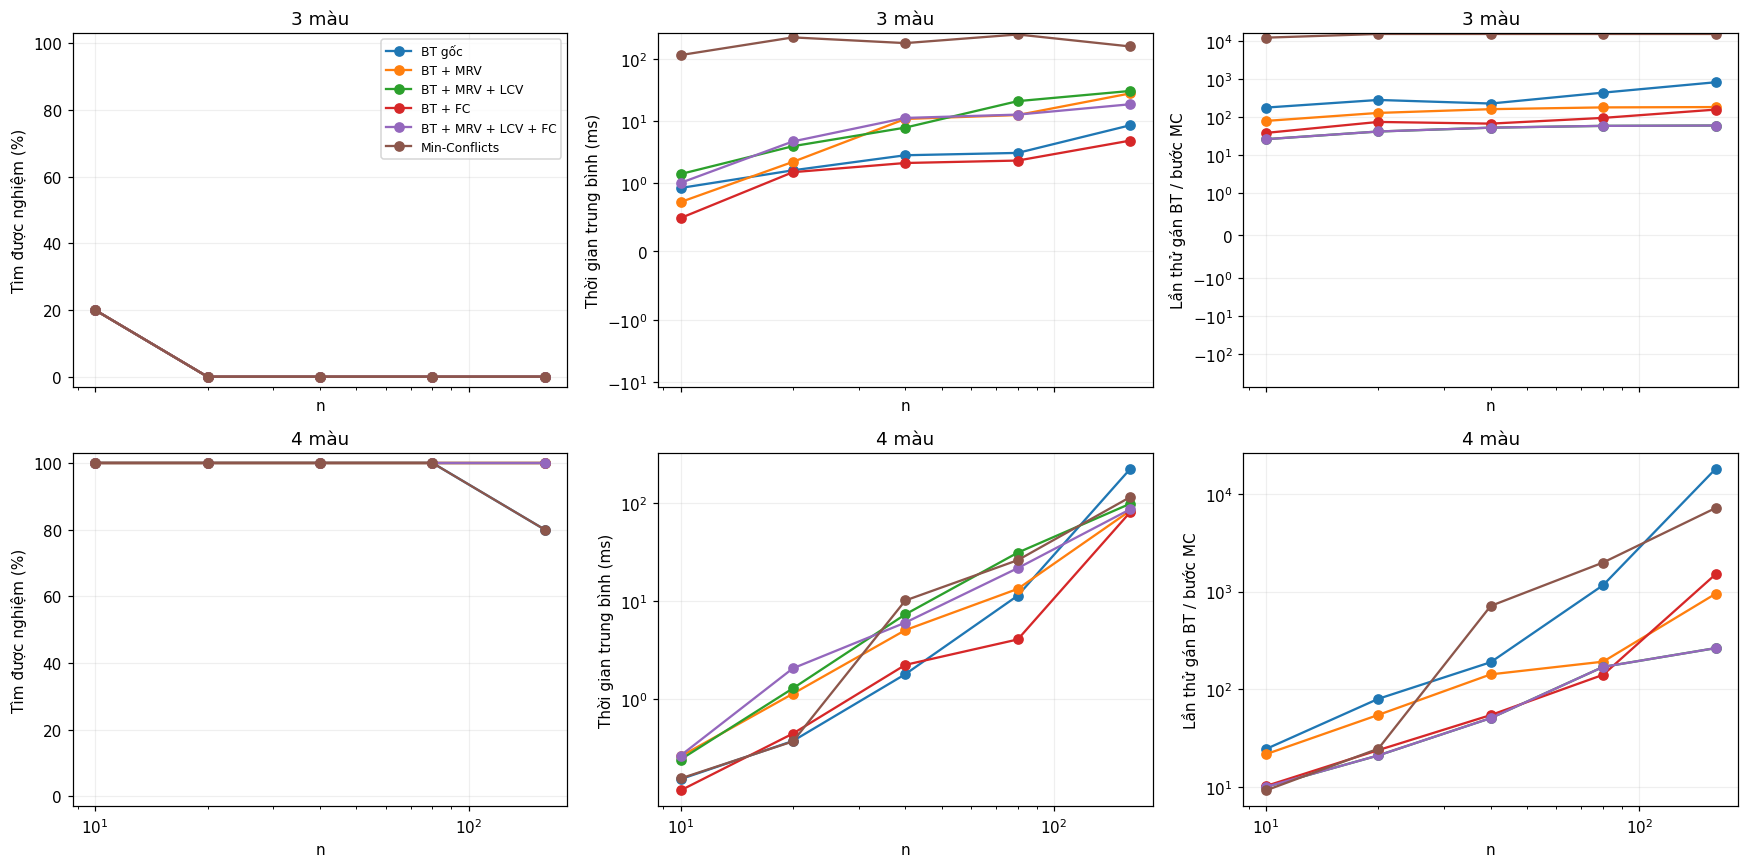

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
for row, k in enumerate([3, 4]):
    for name in [*BT_VARIANTS, 'Min-Conflicts']:
        group = summary[(summary['colors'] == k) & (summary['algorithm'] == name)]
        axes[row, 0].plot(group['n'], group['success_pct'], 'o-', label=name)
        axes[row, 1].plot(group['n'], group['mean_ms'], 'o-', label=name)
        metric = 'mean_steps' if name == 'Min-Conflicts' else 'mean_attempts'
        axes[row, 2].plot(group['n'], group[metric], 'o-', label=name)
    for col, ylabel in enumerate(['Tìm được nghiệm (%)', 'Thời gian trung bình (ms)',
                                  'Lần thử gán BT / bước MC']):
        ax = axes[row, col]
        ax.set(xscale='log', xlabel='n', ylabel=ylabel, title=f'{k} màu')
        ax.grid(alpha=0.2)
        if col:
            ax.set_yscale('symlog', linthresh=1)
    axes[row, 0].set_ylim(-3, 103)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Cách đọc biểu đồ:** cột phải dùng lần thử gán cho Backtracking và bước sửa biến cho
Min-Conflicts; hai đơn vị này có chi phí khác nhau nên chỉ dùng để xem xu hướng từng thuật toán.
Thời gian trung bình gồm lần bị cắt: đường thời gian sát 400 ms phản ánh ngân sách,
không chứng minh thuật toán có độ phức tạp hằng số. MRV/LCV có thể giảm số lần thử nhưng vẫn
tốn thời gian hơn trên bài nhỏ. FC phát hiện sớm miền rỗng; lợi ích tùy cấu trúc đồ thị.

### Thử mở rộng kích thước trong ngân sách

Để đáp ứng yêu cầu “tăng n lớn nhất có thể xử lý”, thử thêm **320 và 640 đỉnh**, mỗi kích thước
**3 seed**, **4 màu**, bằng MRV+LCV+FC và Min-Conflicts. Ngân sách **1 giây/lần chạy**,
Backtracking tối đa **100.000 lần thử**; MC tối đa **10.000 bước/khởi tạo**, **4 restart**.
Đây là thí nghiệm mở rộng riêng, không gộp vào bảng 0,4 giây. “Lớn nhất” ở đây là lớn nhất
đã tìm được nghiệm trong dải kích thước và tài nguyên đã thử, không phải giới hạn lý thuyết.

In [14]:
large_rows = []
for size in [320, 640]:
    for graph_seed in GRAPH_SEEDS[:3]:
        _, _, adjacency = generate_graph(size, graph_seed)
        problem = make_csp(adjacency, COLORS)
        configurations = [
            ('BT + MRV + LCV + FC', backtrack_search,
             dict(variable_order='mrv', value_order='lcv', use_fc=True,
                  max_attempts=100_000, time_limit=1.0)),
            ('Min-Conflicts', min_conflicts,
             dict(seed=graph_seed, max_steps=10_000, max_restarts=4, time_limit=1.0)),
        ]
        for name, solver, options in configurations:
            result = solver(problem, **options)
            large_rows.append(dict(n=size, seed=graph_seed, colors=4, algorithm=name,
                                   edges=len(problem['constraints']), status=result['status'],
                                   seconds=result['seconds'], COUNT=result.get('COUNT', np.nan),
                                   attempts=result.get('attempts', np.nan),
                                   steps=result.get('steps', np.nan),
                                   improving_moves=result.get('improving_moves', np.nan),
                                   restarts=result.get('restarts', np.nan)))
large_raw = pd.DataFrame(large_rows)
large_summary = large_raw.groupby(['n', 'algorithm'], as_index=False).agg(
    runs=('status', 'size'), success_pct=('status', lambda s: 100 * s.eq('solved').mean()),
    mean_ms=('seconds', lambda s: 1000 * s.mean()), mean_edges=('edges', 'mean'),
    mean_COUNT=('COUNT', 'mean'), mean_attempts=('attempts', 'mean'),
    mean_steps=('steps', 'mean'), mean_improving=('improving_moves', 'mean'),
    mean_restarts=('restarts', 'mean'))
display(large_summary.round(3))

,n,algorithm,runs,success_pct,mean_ms,mean_edges,mean_COUNT,mean_attempts,mean_steps,mean_improving,mean_restarts
0,320,BT + MRV + LCV + FC,3,100.000,252.737,943.667,476.667,509.667,NaN,NaN,NaN
1,320,Min-Conflicts,3,0.000,922.068,943.667,NaN,NaN,39262.0,743.333,3.333
2,640,BT + MRV + LCV + FC,3,33.333,893.692,1898.333,751.667,784.000,NaN,NaN,NaN
3,640,Min-Conflicts,3,33.333,745.608,1898.333,NaN,NaN,30370.0,1222.333,2.667


### Nhận xét từ số liệu đã chạy

Các đoạn dưới tạo kết luận trực tiếp từ bảng kết quả. Số lần thử được so sánh trên các cặp
đồ thị mà **cả hai thuật toán đều giải xong** cùng một trạng thái (`solved` hoặc `unsat`),
để tránh gọi một thuật toán hết giờ sớm là tiết kiệm tìm kiếm.

In [15]:
comparisons = []
base = raw[raw['algorithm'].eq('BT gốc')]
for name in list(BT_VARIANTS)[1:]:
    candidate = raw[raw['algorithm'].eq(name)]
    paired = base.merge(candidate, on=['n', 'seed', 'colors'], suffixes=('_base', '_new'))
    paired = paired[(paired['status_base'] != 'limit') &
                    (paired['status_base'] == paired['status_new'])]
    comparisons.append({'thuật toán': name, 'cặp hoàn tất': len(paired),
                        'ít lần thử hơn': int((paired['attempts_new'] < paired['attempts_base']).sum()),
                        'bằng lần thử': int((paired['attempts_new'] == paired['attempts_base']).sum()),
                        'nhanh hơn': int((paired['seconds_new'] < paired['seconds_base']).sum())})
display(pd.DataFrame(comparisons))

lines = []
for k in [3, 4]:
    group = proofs[proofs['colors'].eq(k)]
    counts = group['proof'].value_counts()
    lines.append(f'- **{k} màu:** {counts.get("sat", 0)} đồ thị xác nhận có nghiệm, '
                 f'{counts.get("unsat", 0)} xác nhận vô nghiệm, '
                 f'{counts.get("unknown", 0)} chưa xác định trong ngân sách.')
    mc = raw[(raw['colors'] == k) & (raw['algorithm'] == 'Min-Conflicts')]
    solved = mc[mc['solved']]
    lines.append(f'  Min-Conflicts tìm được nghiệm {len(solved)}/{len(mc)} lần. '
                 + (f'Trong các lần thành công: trung bình {solved["steps"].mean():.1f} bước, '
                    f'{solved["improving_moves"].mean():.1f} bước cải thiện và '
                    f'{solved["restarts"].mean():.2f} restart.' if len(solved) else
                    'Không có lần thành công để tính chi phí đạt nghiệm.'))
for name in ['BT + MRV + LCV + FC', 'Min-Conflicts']:
    completed = large_raw[(large_raw['algorithm'] == name) & (large_raw['status'] == 'solved')]
    lines.append(f'- **{name}, mở rộng:** '
                 + (f'n lớn nhất tìm được nghiệm là **{completed["n"].max()}**.'
                    if len(completed) else 'chưa tìm được nghiệm ở 320/640 đỉnh trong ngân sách.'))
display(Markdown(chr(10).join(lines)))

,thuật toán,cặp hoàn tất,ít lần thử hơn,bằng lần thử,nhanh hơn
0,BT + MRV,49,41,5,11
1,BT + MRV + LCV,49,48,0,9
2,BT + FC,49,49,0,40
3,BT + MRV + LCV + FC,49,48,0,11


- **3 màu:** 1 đồ thị xác nhận có nghiệm, 24 xác nhận vô nghiệm, 0 chưa xác định trong ngân sách.
  Min-Conflicts tìm được nghiệm 1/25 lần. Trong các lần thành công: trung bình 32.0 bước, 5.0 bước cải thiện và 0.00 restart.
- **4 màu:** 25 đồ thị xác nhận có nghiệm, 0 xác nhận vô nghiệm, 0 chưa xác định trong ngân sách.
  Min-Conflicts tìm được nghiệm 24/25 lần. Trong các lần thành công: trung bình 1437.8 bước, 56.8 bước cải thiện và 0.42 restart.
- **BT + MRV + LCV + FC, mở rộng:** n lớn nhất tìm được nghiệm là **640**.
- **Min-Conflicts, mở rộng:** n lớn nhất tìm được nghiệm là **640**.

**Diễn giải và giới hạn kết luận.** MRV ưu tiên biến khó để lộ thất bại sớm, LCV ưu tiên màu
ít hạn chế tương lai, còn FC loại màu và kiểm tra miền rỗng ngay. Đây là lý do về cơ chế;
mức cải thiện thực tế phải đọc bảng cặp hoàn tất ở trên, không mặc định mọi heuristic đều thắng.
Min-Conflicts sửa trực tiếp một phép gán đầy đủ nên có thể tìm nghiệm nhanh khi đi được tới
vùng ít xung đột; chuỗi bước ngang dài hoặc restart cho thấy nó có thể mắc ở plateau/cực tiểu.
Số bước cải thiện không mô tả hết công việc, vì vậy đã báo thêm tổng bước và các bước còn lại.

Với 3 màu, đồ thị vô nghiệm khiến tìm kiếm đầy đủ có thể tốn nhiều công sức để bác bỏ,
còn MC chỉ dừng theo ngân sách. Với 4 màu, các đồ thị phẳng này có nghiệm, nhưng thuật toán
vẫn có thể hết ngân sách trước khi tìm ra. Kết quả từ 5 đồ thị mỗi nhóm chỉ là thực nghiệm
quy mô nhỏ; seed cố định giúp tái lập, không bảo đảm đại diện cho mọi đồ thị.
Không suy ra Big-O từ vài điểm bị giới hạn thời gian.

## Lưu kết quả và kiểm tra bài nộp

Lưu số liệu thô, bảng tổng hợp và thiết lập thực nghiệm để đối chiếu với hình/bảng.
Notebook này chứa đầy đủ mã và đầu ra; bản HTML cho phép đọc kết quả không cần chạy Python.

In [16]:
from pathlib import Path
import json
import scipy
import matplotlib

# Khi mở từ gốc repository hoặc từ thư mục lab đều lưu đúng vị trí.
lab_dir = Path.cwd()
if (lab_dir / 'weekly assignments' / 'lab04 - csp').is_dir():
    lab_dir = lab_dir / 'weekly assignments' / 'lab04 - csp'
result_dir = lab_dir / 'results'
result_dir.mkdir(exist_ok=True)
for filename, frame in {
    'graph_edges.csv': edge_data,
    'edge_summary.csv': edge_summary,
    'benchmark_raw.csv': raw,
    'benchmark_summary.csv': summary,
    'success_only.csv': success_only,
    'known_sat_success.csv': known_sat,
    'instance_proofs.csv': proofs,
    'large_graph_raw.csv': large_raw,
    'large_graph_summary.csv': large_summary,
}.items():
    frame.to_csv(result_dir / filename, index=False, encoding='utf-8-sig')
settings = {
    'sizes': SIZES, 'graph_seeds': GRAPH_SEEDS, 'colors': [3, 4],
    'time_limit_seconds': TIME_LIMIT, 'bt_max_attempts': MAX_ATTEMPTS,
    'mc_max_steps_per_start': 3000, 'mc_max_restarts': 4,
    'large_sizes': [320, 640], 'large_graph_seeds': GRAPH_SEEDS[:3],
    'large_colors': [4], 'large_time_limit_seconds': 1.0,
    'large_bt_max_attempts': 100_000, 'large_mc_max_steps_per_start': 10_000,
    'large_mc_max_restarts': 4,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                 'scipy': scipy.__version__, 'pandas': pd.__version__,
                 'matplotlib': matplotlib.__version__},
    'timing_scope': 'solver only; includes initialization; excludes graph generation and rendering',
}
(result_dir / 'settings.json').write_text(json.dumps(settings, ensure_ascii=False, indent=2), encoding='utf-8')
assert len(raw) == len(SIZES) * len(GRAPH_SEEDS) * 2 * (len(BT_VARIANTS) + 1)
assert not raw['status'].isna().any()
assert set(raw.loc[raw['algorithm'].eq('Min-Conflicts'), 'status']) <= {'solved', 'limit'}
print('Đã lưu 9 bảng CSV và settings.json vào results/.')
print('Hoàn tất 4 bài, kiểm thử và Assignment mở rộng của notebook tô màu.')

Đã lưu 9 bảng CSV và settings.json vào results/.
Hoàn tất 4 bài, kiểm thử và Assignment mở rộng của notebook tô màu.
